# Dlinear Stress Test Project in AIO 2026 - Experimental setup

Ở đây mình sẽ xây dựng và đánh giá pipeline thực nghiệp sử dụng cho dự án Dlinear stress test
this notebook builds and validates the experimental pipeline used for the dlinear stress-test study

## Pipeline

- sliding window (L-> T)
- Linear/dlinear/nlinear
- training
- forecasting
- mse/mae

In [48]:
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from sklearn.metrics import mean_squared_error, mean_absolute_error

from torch.utils.data import DataLoader, TensorDataset

In [2]:
# kiểm tra lại environment

print("numpy", np.__version__)
print("pandas", pd.__version__)
print("matplotlib", plt.matplotlib.__version__)
print("scikit-learn", __import__('sklearn').__version__)
print("torch", torch.__version__)

numpy 2.5.3
pandas 3.0.6
matplotlib 3.11.2
scikit-learn 1.9.1
torch 2.14.0


### Tạo một data giả lập synthetic data
Data này tôi có thể kiểm soát thay vì việc sử dụng một bộ dữ liệu thực tế thường chứa nhiều nhiễu mà tôi chưa biết trước được, việc tự sinh ra data thế này giúp tôi có thể nắm bản chất thật của nó để đánh giá tính chính xác của mô hình.

nó dựa trên: X(t) = Trend + Seasonality + Noise

Với những cài đặt P của tôi thì tôi có thể biết được đáp án đó liệu có đúng hay không, ví dụ tôi cài P=24 khi kiểm tra xem mô hình có tìm ra chu kì P hay không thì tôi có thể đoán được mô hình đang đúng hay k.

#### Function generate time series data

In [16]:
def generate_series(length = 500, period = 24, amplitude = 1.0, trend_slope = 0.0, noise_std = 0.0, phase = 0.0, seed = 42):
    rng = np.random.default_rng(seed)
    t = np.arange(length)
    trend = trend_slope * t
    periodic = amplitude * np.sin(2 * np.pi * t / period + phase)
    noise = rng.normal(loc = 0.0, scale = noise_std, size = length)
    series = trend + periodic + noise
    return t, series, trend, periodic, noise


Generated time series data

In [17]:
t, series, trend, periodic, noise = generate_series(length = 500, period = 24, amplitude = 1.0, trend_slope = 0.01, noise_std = 0.1, phase = 0.0, seed = 42)

In [18]:
series[0:10]

array([0.03047171, 0.16482063, 0.59504512, 0.83116325, 0.71092188,
       0.88570788, 1.07278404, 1.00430157, 0.94434529, 0.71180239])

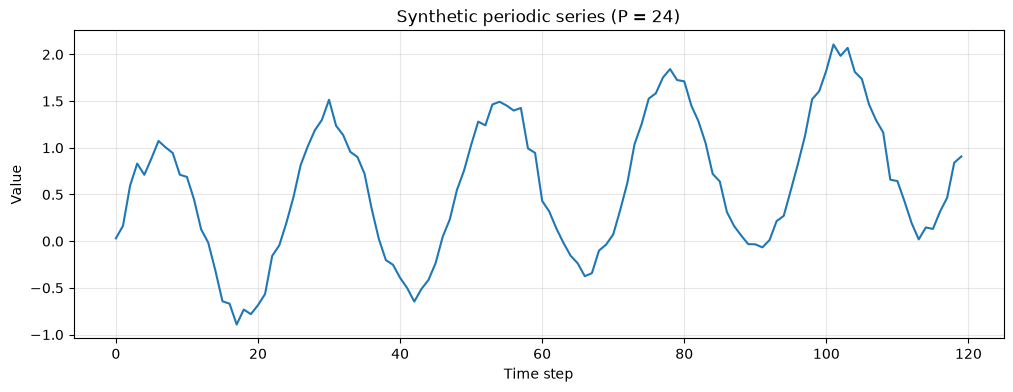

In [19]:
plt.figure(figsize=(12, 4))
plt.plot(t[:120], series[:120]) # plot the first 120 time steps
plt.xlabel("Time step")
plt.ylabel("Value")
plt.title("Synthetic periodic series (P = 24)")
plt.grid(alpha=0.3)
plt.show()

Vì tớ set P=24 nên khi vẽ ra 120 điểm dữ liệu thì nó sẽ chia thành 120/24 = 5 khoảng chu kì hoàn chỉnh để dễ nhận biết

In [20]:
# thử thêm trend và noise vào series

t, series_with_trend_noise, trend, periodic, noise = generate_series(length = 500, period = 24, amplitude = 1.0, trend_slope = 0.01, noise_std = 0.1, phase = 0.0, seed = 42)

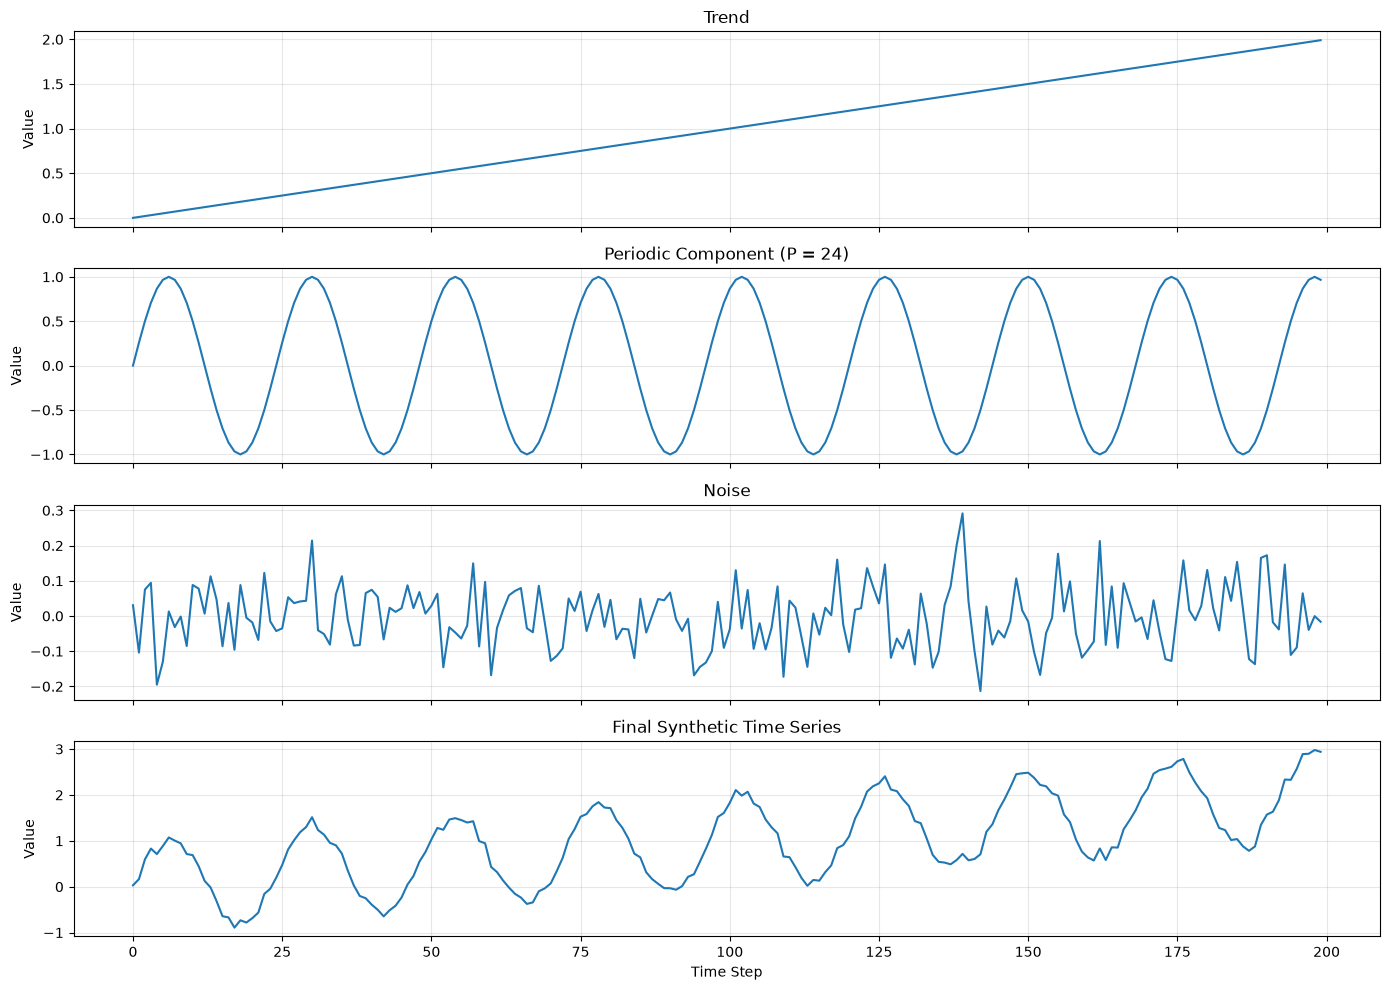

In [21]:
n = 200

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)

# 1. Trend
axes[0].plot(t[:n], trend[:n])
axes[0].set_title("Trend")
axes[0].set_ylabel("Value")
axes[0].grid(alpha=0.3)

# 2. Periodic component
axes[1].plot(t[:n], periodic[:n])
axes[1].set_title("Periodic Component (P = 24)")
axes[1].set_ylabel("Value")
axes[1].grid(alpha=0.3)

# 3. Noise
axes[2].plot(t[:n], noise[:n])
axes[2].set_title("Noise")
axes[2].set_ylabel("Value")
axes[2].grid(alpha=0.3)

# 4. Final series
axes[3].plot(t[:n], series[:n])
axes[3].set_title("Final Synthetic Time Series")
axes[3].set_xlabel("Time Step")
axes[3].set_ylabel("Value")
axes[3].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Biểu đồ đầu tiên với trend = 0.01 nên nó tạo thành 1 đường thẳng tăng dần
tại t = 0 -> trend = 0, tại t = 200 -> trend = 0.01 * 200 = 2

Với periodict thì $S_t = \sin\left(\frac{2\pi t}{24}\right).$
wave lặp lại mỗi P=24 => 200/24 = 8.33 chu kì

In [22]:
print(f"Series length : {len(series)}")
print(f"Period : {24}")
print(f"Trend start : {trend[0]:.4f}")
print(f"Trend end : {trend[-1]:.4f}")
print(f"Noise mean : {noise.mean():.4f}")
print(f"Noise std : {noise.std():.4f}")

Series length : 500
Period : 24
Trend start : 0.0000
Trend end : 4.9900
Noise mean : -0.0013
Noise std : 0.0959


In [25]:
P = 24
periodic_error = np.mean(np.abs(periodic[:-P] - periodic[P:]))

print("periodicity error:", periodic_error)

periodicity error: 3.138335946314399e-15


In [26]:
# sliding window approach to create input-output pairs for supervised learning

def create_windows(series, lookback, horizon): #lookback: số lượng bước thời gian in past dùng làm input X, horizon: số lượng bước thời gian in future dùng làm output y
    X, y = [], []
    for i in range(len(series) - lookback - horizon + 1):
        X.append(series[i:i + lookback])
        y.append(series[i + lookback:i + lookback + horizon])
    return np.array(X), np.array(y)

In [28]:
L = 48 # lookback window size
T = 24 # horizon window size

X, y = create_windows(series, lookback=L, horizon=T)

print(f"X: {X.shape}, y: {y.shape}")

X: (429, 48), y: (429, 24)


## Builds Linear model

Vì chuẩn bị sử dụng pytorch nên trước tiên em sẽ chuyển Numpy array -> tensor

In [29]:
X_tensor = torch.tensor(X, dtype=torch.float32)
y_tensor = torch.tensor(y, dtype=torch.float32)

print(f"X_tensor: {X_tensor.shape}, y_tensor: {y_tensor.shape}")

X_tensor: torch.Size([429, 48]), y_tensor: torch.Size([429, 24])


### 1. Linear

#### Mô hình Baseline Tuyến tính (Linear Baseline)

Đây là mô hình đơn giản nhất nhưng đóng vai trò là cột mốc (baseline) rất quan trọng trong đánh giá performance. 

* **Công thức toán học:**  
  $$\hat{\boldsymbol{Y}} = \boldsymbol{W}\boldsymbol{X} + b$$
  * Đầu vào (Input): $\boldsymbol{X} \in \mathbb{R}^L$ (chuỗi dữ liệu quá khứ độ dài $L$).
  * Đầu ra (Output): $\hat{\boldsymbol{Y}} \in \mathbb{R}^T$ (chuỗi dữ liệu dự báo độ dài $T$).
  * Ma trận trọng số: $\boldsymbol{W} \in \mathbb{R}^{T \times L}$ kết nối trực tiếp $L$ bước quá khứ với $T$ bước tương lai.

* **Bản chất:** Mô hình thực hiện một phép ánh xạ tuyến tính trực tiếp từ không gian quá khứ sang không gian tương lai. Ví dụ với $L = 48$ và $T = 24$, mô hình học ánh xạ:
  $$\mathbb{R}^{48} --> \mathbb{R}^{24}$$

In [ ]:
class LinearModel(nn.Module): #kế thừa từ nn.Module để có được những tính năng như quản lý para, huấn luyện, lan truyền ngược backpropagation
    def __init__(self, lookback, horizon):
        super().__init__()

        self.linear = nn.Linear(in_features=lookback, out_features=horizon)

    def forward(self, x):
        return self.linear(x)

In [31]:
linear_model = LinearModel(lookback=L, horizon=T)
print(linear_model)

LinearModel(
  (linear): Linear(in_features=48, out_features=24, bias=True)
)


In [ ]:
X_batch = X_tensor[:32]  # Lấy 32 mẫu đầu tiên từ X_tensor
print(f"X_batch: {X_batch.shape}")

X_batch: torch.Size([32, 48])


In [ ]:
with torch.no_grad(): #tạm dừng tính toán gradient
    y_pred = linear_model(X_batch)
    print(f"y_pred: {y_pred.shape}")

y_pred: torch.Size([32, 24])


Kích thước (Shape) của Tensor khớp hoàn toàn với thiết kế

* Đầu vào X_batch có kích thước: [32, 48] (32 mẫu trong batch, mỗi mẫu chứa 48 bước lịch sử L = 48$).
* Đầu ra y_pred trả về đúng kích thước: [32, 24] (32 mẫu trong batch, mỗi mẫu dự báo 24 bước tương lai T = 24$).

Vì nn.Linear(in_features=48, out_features=24) đã thực hiện đúng phép biến đổi ma trận $[32 \times 48] --> [32 \times 24]$ mà không gặp lỗi lệch chiều (Dimension Mismatch Error), nên về mặt architecture là hợp lệ.

### 2. Dlinear

Khác với mô hình Linear thông thường xử lý trực tiếp toàn bộ dữ liệu, DLinear giải quyết bài toán chuỗi thời gian bằng cách tách dữ liệu đầu vào $X$ thành hai thành phần trước khi dự báo: $X = X_{trend} + X_{remainder}$. Trong đó, $X_{trend}$ thể hiện xu hướng tăng/giảm tổng thể dài hạn (được tính bằng phương pháp Trung bình động - Moving Average), còn $X_{remainder}$ là phần dư còn lại đại diện cho các dao động ngắn hạn ($X_{remainder} = X - X_{trend}$).

Mặc dù bài báo gốc gọi phần dư này là seasonal, nhưng về bản chất nó chỉ là phép trừ đơn giản sau trung bình động chứ không dùng thuật toán phân tích chu kỳ phức tạp (như Fourier hay STL), do đó gọi chính xác là $X_{remainder}$ phần dư sẽ chuẩn xác hơn.

In [34]:
# sử dụng AvgPool1d

class MovingAverage(nn.Module):
    def __init__(self, kernel_size):
        super().__init__()

        self.kernel_size = kernel_size
        self.avg_pool = nn.AvgPool1d(kernel_size=kernel_size, stride=1)

    def forward(self, x):

        pad = (self.kernel_size - 1) // 2
        front = x[:, :1].repeat(1, pad) #sử dụng padding 2 đầu để output vẫn giữ chiều dài
        end = x[:, -1:].repeat(1, pad)
        x_padded = torch.cat([front, x, end], dim=1)
        trend = self.avg_pool(x_padded.unsqueeze(1)).squeeze(1)

        return trend

In [ ]:
# test thử moving average

moving_avg = MovingAverage(kernel_size=5)
trend_batch = moving_avg(X_batch)

print("Input :", X_batch.shape)
print("Trend :", trend_batch.shape)

Input : torch.Size([32, 48])
Trend : torch.Size([32, 48])


In [36]:
remainder_batch = X_batch - trend_batch
print(remainder_batch.shape)

torch.Size([32, 48])


In [37]:
reconstructed = trend_batch + remainder_batch
error = torch.mean(torch.abs(X_batch - reconstructed))

print("Reconstruction error:", error.item())

Reconstruction error: 6.548361852765083e-11


về mặt lý thuyết, nếu phép phân tách chính xác thì kết quả tái tạo ngược lại của reconstructed = X_batch
em sử dụng bước này dùng để kiểm thử logic code để đảm bảo thuật toán phân tách bằng moving avg không bị lỗi tính toán.

In [38]:
class DLinear(nn.Module):
    def __init__(self, lookback, horizon, kernel_size=5):
        super().__init__()

        self.moving_avg = MovingAverage(kernel_size=kernel_size)

        self.linear_trend = nn.Linear(lookback, horizon)

        self.linear_remainder = nn.Linear(lookback, horizon)

    def forward(self, x):

        trend = self.moving_avg(x)

        remainder = x - trend
        
        trend_output = self.linear_trend(trend)

        remainder_output = self.linear_remainder(remainder)

        output = (trend_output + remainder_output)

        return output

$$X_{trend} = MovingAverage(X)$$

$$X_{remainder} = X - X_{trend}$$

sau đó:

$$\hat{Y}_{trend} = W_{trend} X_{trend} + b_{trend}$$

$$\hat{Y}_{remainder} = W_{remainder} X_{remainder} + b_{remainder}$$

và cuối cùng:

$$\hat{Y} = \hat{Y}_{trend} + \hat{Y}_{remainder}$$

In [39]:
# test Dlinear model

dlinear_model = DLinear(lookback=L, horizon=T, kernel_size=5)

with torch.no_grad():
    y_pred = dlinear_model(X_batch)

print("Input :", X_batch.shape)
print("Output:", y_pred.shape)

Input : torch.Size([32, 48])
Output: torch.Size([32, 24])


### 3. Nlinear



In [40]:
class NLinear(nn.Module):
    def __init__(self, lookback, horizon):
        super().__init__()

        self.linear = nn.Linear(lookback, horizon)

    def forward(self, x):

        last_value = x[:, -1:]

        normalized = x - last_value

        output = self.linear(normalized)

        output = output + last_value

        return output

In [41]:
nlinear_model = NLinear(lookback=L, horizon=T)

with torch.no_grad():
    y_pred = nlinear_model(X_batch)

print("Input :", X_batch.shape)
print("Output:", y_pred.shape)

Input : torch.Size([32, 48])
Output: torch.Size([32, 24])


In [42]:
models = {"Linear": LinearModel(L, T), "DLinear": DLinear(L, T, kernel_size=5), "NLinear": NLinear(L, T),}

for name, model in models.items():

    with torch.no_grad():
        output = model(X_batch)

    print(f"{name:8s} | "f"Input: {tuple(X_batch.shape)} | "f"Output: {tuple(output.shape)}")

Linear   | Input: (32, 48) | Output: (32, 24)
DLinear  | Input: (32, 48) | Output: (32, 24)
NLinear  | Input: (32, 48) | Output: (32, 24)


# Tranning & evaluation pipeline

Đầu tiên, em muốn xác nhận quy trình dự báo hoàn chỉnh bằng cách chạy thử nghiệm luồng huấn huyện và đánh giá trên 1 cấu hình cố định trước khi vào thực nghiệm.



In [43]:
# generated data

P = 24
L = 96
T = 24

t, series, trend, periodic, noise = generate_series(length=5000, period=P, amplitude=1.0, trend_slope=0.0, noise_std=0.0, seed=42)

print("Series length:", len(series))
print("L/P:", L / P)
print("T/P:", T / P)

Series length: 5000
L/P: 4.0
T/P: 1.0


Mô hình sẽ quan sát 4 chu kỳ lịch sử liên tiếp ($L = 96$, tức 4 lần lặp lại của chu kỳ 24 bước) để dự báo 1 chu kỳ tiếp theo trong tương lai ($T = 24$).

Đây là bài toán dự báo ở mức "dễ" và có tính lặp lại rất rõ ràng.

=> Nếu mô hình không thể học được quy luật (signal) rõ ràng từ 4 chu kỳ quá khứ này, chứng tỏ quy trình (pipeline) đang gặp lỗi lập trình hoặc thiết lập dữ liệu bị sai.

### train test split

Với 5000 điểm dữ liệu thì em sẽ chia thành 70% cho train, 15% cho validation, 15% còn lại cho test

In [44]:
train_ratio = 0.70
val_ratio = 0.15

n = len(series)

train_end = int(n * train_ratio)
val_end = int(n * (train_ratio + val_ratio))

train_series = series[:train_end]
val_series = series[train_end:val_end]
test_series = series[val_end:]

print("Train:", len(train_series))
print("Val  :", len(val_series))
print("Test :", len(test_series))

Train: 3500
Val  : 750
Test : 750


In [45]:
X_train, y_train = create_windows(train_series, lookback=L, horizon=T)

X_val, y_val = create_windows(val_series, lookback=L, horizon=T)

X_test, y_test = create_windows(test_series, lookback=L, horizon=T)

print("Train:", X_train.shape, y_train.shape)
print("Val  :", X_val.shape, y_val.shape)
print("Test :", X_test.shape, y_test.shape)

Train: (3381, 96) (3381, 24)
Val  : (631, 96) (631, 24)
Test : (631, 96) (631, 24)


In [46]:
# chuyển dữ liệu sang tensor

X_train = torch.tensor(X_train, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32)

X_val = torch.tensor(X_val, dtype=torch.float32)
y_val = torch.tensor(y_val, dtype=torch.float32)

X_test = torch.tensor(X_test, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.float32)

In [47]:
print(X_train.shape)
print(y_train.shape)

torch.Size([3381, 96])
torch.Size([3381, 24])


In [49]:
# đóng gói dữ liệu tensor thành bộ dữ liệu tiêu chuẩn cho cả 3 tập
# kích thước batch là 32

batch_size = 32

train_dataset = TensorDataset(X_train, y_train)

val_dataset = TensorDataset(X_val, y_val)

test_dataset = TensorDataset(X_test, y_test)

In [ ]:
# tạo pipeline DataLoader cho cả 3 tập dữ liệu

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True) #không shuffer khi chia nhưng có thể suffer trong quá trình huấn luyện để tăng tính tổng quát hóa của mô hình

val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False) #không shuffer để giữ thứ tự

test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

In [51]:
X_batch, y_batch = next(iter(train_loader))

print("Input batch :", X_batch.shape)
print("Target batch:", y_batch.shape)

Input batch : torch.Size([32, 96])
Target batch: torch.Size([32, 24])


In [52]:
# em sử dụng MSE cho hàm loss

criterion = nn.MSELoss()

In [53]:
def train_one_epoch(model, train_loader, criterion, optimizer):
    model.train()

    total_loss = 0.0

    for X_batch, y_batch in train_loader:

        optimizer.zero_grad() # 1. Reset gradient

        y_pred = model(X_batch)

        loss = criterion(y_pred, y_batch) #tính loss

        loss.backward() #backpropagation 

        optimizer.step() # cập nhật trọng số

        total_loss += loss.item() * X_batch.size(0) #tích luỹ loss cho tất cả các batch

    average_loss = total_loss / len(train_loader.dataset)

    return average_loss

In [54]:
# validation
def validate(model, val_loader, criterion):
    model.eval()

    total_loss = 0.0

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            # Forward
            y_pred = model(X_batch)

            # Calculate loss
            loss = criterion(y_pred, y_batch)

            # Accumulate loss
            total_loss += loss.item() * X_batch.size(0)

    average_loss = total_loss / len(val_loader.dataset)

    return average_loss

In [ ]:
# test thử LienarModel

model = LinearModel(lookback=L, horizon=T)

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)


In [56]:
train_loss = train_one_epoch(model, train_loader, criterion, optimizer)

print("Train MSE:", train_loss)

Train MSE: 0.06139372126350807


In [57]:
val_loss = validate(model, val_loader, criterion)

print("Validation MSE:", val_loss)

Validation MSE: 0.00028040025659236117


Đến đây thì pipeline hoạt động ổn

In [58]:
def train_model(model, train_loader, val_loader, epochs=50, learning_rate=1e-3):
    criterion = nn.MSELoss()

    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    train_losses = []
    val_losses = []

    for epoch in range(epochs):

        train_loss = train_one_epoch(model, train_loader, criterion, optimizer)

        val_loss = validate(model, val_loader, criterion)

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        if epoch == 0 or (epoch + 1) % 10 == 0:

            print(
                f"Epoch {epoch + 1:3d}/{epochs} | "
                f"Train MSE: {train_loss:.6f} | "
                f"Val MSE: {val_loss:.6f}"
            )

    return train_losses, val_losses

In [61]:
#cố định seed để đảm bảo kết quả có thể tái tạo được
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed(42)

In [62]:
#train linear model
linear_model = LinearModel(lookback=L, horizon=T)

print(linear_model)

LinearModel(
  (linear): Linear(in_features=96, out_features=24, bias=True)
)


In [63]:
linear_train_losses, linear_val_losses = train_model(model=linear_model, train_loader=train_loader, val_loader=val_loader, epochs=50, learning_rate=1e-3)

Epoch   1/50 | Train MSE: 0.054048 | Val MSE: 0.000129
Epoch  10/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  20/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  30/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  40/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  50/50 | Train MSE: 0.000000 | Val MSE: 0.000000


Model hoạt động tốt, train loss đang giảm = optimizer đang được học


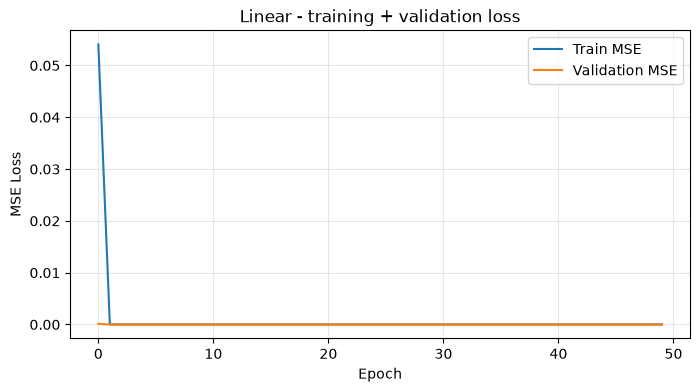

In [66]:
#Trực quan hóa kết quả huấn luyện và validation loss
plt.figure(figsize=(8, 4))

plt.plot(linear_train_losses, label="Train MSE")

plt.plot(linear_val_losses, label="Validation MSE")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Linear - training + validation loss")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [ ]:
#hàm đánh giá MAE và MSE

def evaluate_model(model, data_loader):
    model.eval() #sử dụng model evaluation mode để tắt dropout và batch normalization

    predictions = []
    targets = []

    with torch.no_grad(): # không tính gradient nữa

        for X_batch, y_batch in data_loader:

            y_pred = model(X_batch)

            predictions.append(y_pred.cpu().numpy()) # gom prediction từ mỗi batch tạo ra

            targets.append(y_batch.cpu().numpy())

    predictions = np.concatenate(predictions, axis=0)

    targets = np.concatenate(targets, axis=0)

    mse = mean_squared_error(targets.flatten(), predictions.flatten())

    mae = mean_absolute_error(targets.flatten(), predictions.flatten())

    return mse, mae, predictions, targets

In [70]:
linear_mse, linear_mae, linear_predictions, test_targets = evaluate_model(linear_model, test_loader)

print(f"Linear test MSE : {linear_mse:.6f}")
print(f"Linear test MAE : {linear_mae:.6f}")
print("Prediction :", linear_predictions.shape)
print("Target :", test_targets.shape)

Linear test MSE : 0.000000
Linear test MAE : 0.000020
Prediction : (631, 24)
Target : (631, 24)


ở đây em đang muốn xem xem MSE và MAE có đang tính được không, shape của prediction có ok không?

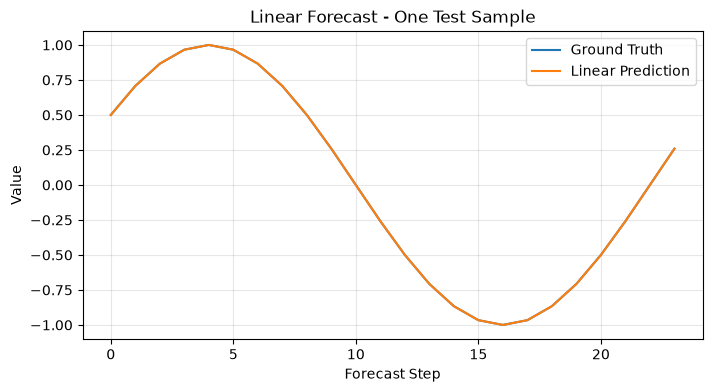

In [ ]:
# visualize một forecast
sample_id = 0 
true_future = test_targets[sample_id]
predicted_future = linear_predictions[sample_id]

plt.figure(figsize=(8, 4))

plt.plot(true_future, label="Ground Truth")

plt.plot(predicted_future, label="Linear Prediction")

plt.xlabel("Forecast Step")
plt.ylabel("Value")
plt.title("Linear Forecast - One Test Sample")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

Model đang học tốt

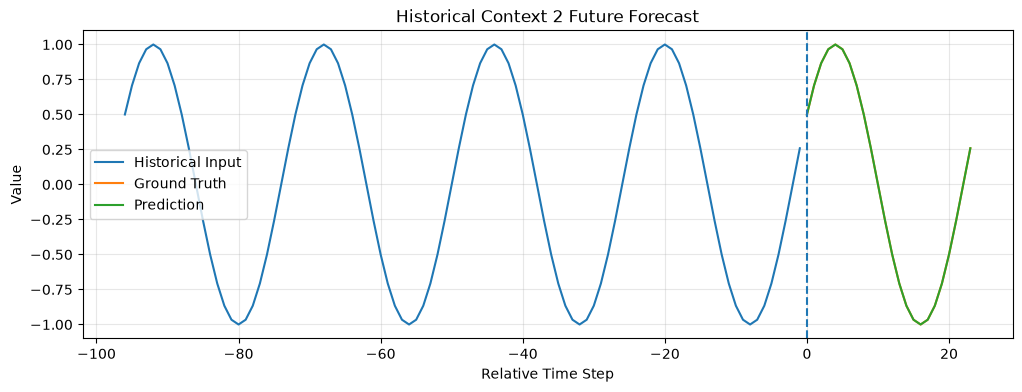

In [74]:
sample_id = 0

history = X_test[sample_id].numpy()
true_future = test_targets[sample_id]
pred_future = linear_predictions[sample_id]

history_steps = np.arange(-L, 0)
future_steps = np.arange(0, T)

plt.figure(figsize=(12, 4))

plt.plot(history_steps, history, label="Historical Input")

plt.plot(future_steps, true_future, label="Ground Truth")

plt.plot(future_steps, pred_future, label="Prediction")

plt.axvline(x=0, linestyle="--")

plt.xlabel("Relative Time Step")
plt.ylabel("Value")
plt.title("Historical Context 2 Future Forecast")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

Mô hình đã học được chu juf từ 96 bước trong quá khứ để dự đoán 24 bước tương lai, không gặp lỗi lệch pha trong pipeline dữ liệu

In [75]:
# reset seed và tạo lại model DLinear

set_seed(42)

dlinear_model = DLinear(lookback=L, horizon=T, kernel_size=5)

In [76]:
# train dlinear
dlinear_train_losses, dlinear_val_losses = train_model(model=dlinear_model, train_loader=train_loader, val_loader=val_loader, epochs=50, learning_rate=1e-3)

Epoch   1/50 | Train MSE: 0.052109 | Val MSE: 0.000097
Epoch  10/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  20/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  30/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  40/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  50/50 | Train MSE: 0.000000 | Val MSE: 0.000002


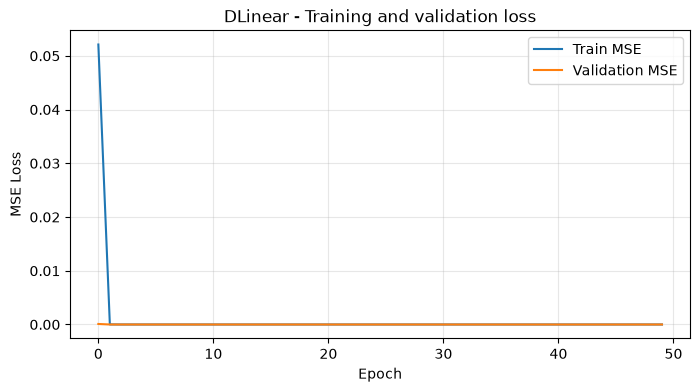

In [77]:
plt.figure(figsize=(8, 4))

plt.plot(dlinear_train_losses, label="Train MSE")

plt.plot(dlinear_val_losses, label="Validation MSE")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("DLinear - Training and validation loss")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [78]:
# evaluate dlinear model
dlinear_mse, dlinear_mae, dlinear_predictions, _ = evaluate_model(dlinear_model, test_loader)

print(f"DLinear Test MSE : {dlinear_mse:.6f}")
print(f"DLinear Test MAE : {dlinear_mae:.6f}")

DLinear Test MSE : 0.000002
DLinear Test MAE : 0.000468


In [79]:
# reset seed và tạo lại model Nlinear
set_seed(42)

nlinear_model = NLinear(lookback=L,horizon=T)

In [80]:
# train Nlinear
nlinear_train_losses, nlinear_val_losses = train_model(model=nlinear_model, train_loader=train_loader, val_loader=val_loader, epochs=50, learning_rate=1e-3)

Epoch   1/50 | Train MSE: 0.100405 | Val MSE: 0.000277
Epoch  10/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  20/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  30/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  40/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  50/50 | Train MSE: 0.000000 | Val MSE: 0.000000


In [81]:
# evaluate dlinear model
nlinear_mse, nlinear_mae, nlinear_predictions, _ = evaluate_model(nlinear_model, test_loader)

print(f"NLinear test MSE : {nlinear_mse:.6f}")
print(f"NLinear test MAE : {nlinear_mae:.6f}")

NLinear test MSE : 0.000000
NLinear test MAE : 0.000025


In [84]:
# compare the performance of the three models
comparison = pd.DataFrame({
    "Model": ["Linear", "DLinear", "NLinear"],
    "MSE": [linear_mse, dlinear_mse, nlinear_mse],
    "MAE": [linear_mae, dlinear_mae, nlinear_mae]
})

comparison["P"] = P
comparison["L"] = L
comparison["T"] = T

comparison["L/P"] = L / P
comparison["T/P"] = T / P

comparison

,Model,MSE,MAE,P,L,T,L/P,T/P
0,Linear,9.334286e-09,0.000020,24,96,24,4.0,1.0
1,DLinear,2.273362e-06,0.000468,24,96,24,4.0,1.0
2,NLinear,1.027320e-08,0.000025,24,96,24,4.0,1.0
